<div style=" background-color: RGB(0,114,200);" >
<h1 style="margin: auto; padding: 20px 0; color:#fff; text-align: center">PROJET 4 DATA ANALYST</h1>
<h2 style="margin: auto; padding: 20px 0; color:#fff; text-align: center">Réalisez une étude de santé publique avec R ou Python
</h2>
</div>

# OBJECTIF DE CE NOTEBOOK

Bienvenue dans l'outil plébiscité par les analystes de données Jupyter.

Il s'agit d'un outil permettant de mixer et d'alterner codes, textes et graphique.

Cet outil est formidable pour plusieurs raisons:

+ il permet de tester des lignes de codes au fur et à mesure de votre rédaction, de constater immédiatement le résultat d'un instruction, de la corriger si nécessaire.
+ De rédiger du texte pour expliquer l'approche suivie ou les résultats d'une analyse et de le mettre en forme grâce à du code html ou plus simple avec **Markdown**
+ d'agrémenter de graphiques

Pour vous aider dans vos premiers pas à l'usage de Jupyter et de Python, nous avons rédigé ce notebook en vous indiquant les instructions à suivre.

Il vous suffit pour cela de saisir le code Python répondant à l'instruction donnée.

Vous verrez de temps à autre le code Python répondant à une instruction donnée mais cela est fait pour vous aider à comprendre la nature du travail qui vous est demandée.

Et garder à l'esprit, qu'il n'y a pas de solution unique pour résoudre un problème et qu'il y a autant de résolutions de problèmes que de développeurs ;)...



<div style="background-color: RGB(0,150,250);" >
<h2 style="margin: auto; padding: 20px; color:#fff; ">Etape 1 - Importation des librairies et chargement des fichiers</h2>
</div>

<div style="border: 1px solid RGB(0,150,250);" >
<h3 style="margin: auto; padding: 20px; color: RGB(0,150,250); ">1.1 - Importation des librairies</h3>
</div>

In [1]:
#Importation de la librairie Pandas
import pandas as pd

In [2]:
import matplotlib.pyplot as plt
import seaborn as sns

import plotly.express as px
import plotly.graph_objects as go

<div style="border: 1px solid RGB(0,150,250);" >
<h3 style="margin: auto; padding: 20px; color: RGB(0,150,250); ">1.2 - Chargement des fichiers Excel</h3>
</div>

In [3]:
#Importation du fichier population.csv
population = pd.read_csv('data/population.csv')

#Importation du fichier dispo_alimentaire.csv
dispo_alimentaire = pd.read_csv('data/dispo_alimentaire.csv')

#Importation du fichier aide_alimentaire.csv
aide_alimentaire = pd.read_csv('data/aide_alimentaire.csv')

#Importation du fichier sous_nutrition.csv
sous_nutrition = pd.read_csv('data/sous_nutrition.csv')

<div style="background-color: RGB(0,150,250);" >
<h2 style="margin: auto; padding: 20px; color:#fff; ">Etape 2 - Analyse exploratoire des fichiers</h2>
</div>

<div style="border: 1px solid RGB(0,150,250);" >
<h3 style="margin: auto; padding: 20px; color: RGB(0,150,250); ">2.1 - Analyse exploratoire du fichier population</h3>
</div>

In [4]:
#Afficher les dimensions du dataset
print("Le tableau comporte {} observation(s) ou article(s)".format(population.shape[0]))
print("Le tableau comporte {} colonne(s)".format(population.shape[1]))

Le tableau comporte 1416 observation(s) ou article(s)
Le tableau comporte 3 colonne(s)


In [5]:
#Consulter le nombre de colonnes
print("Population {}".format(population.shape[1]))
#La nature des données dans chacune des colonnes
print(population.info())
#Le nombre de valeurs présentes dans chacune des colonnes

Population 3
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1416 entries, 0 to 1415
Data columns (total 3 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Zone    1416 non-null   object 
 1   Année   1416 non-null   int64  
 2   Valeur  1416 non-null   float64
dtypes: float64(1), int64(1), object(1)
memory usage: 33.3+ KB
None


In [6]:
#Affichage les 5 premières lignes de la table
population.head(5)

,Zone,Année,Valeur
0,Afghanistan,2013,32269.589
1,Afghanistan,2014,33370.794
2,Afghanistan,2015,34413.603
3,Afghanistan,2016,35383.032
4,Afghanistan,2017,36296.113


In [7]:
#Nous allons harmoniser les unités. Pour cela, nous avons décidé de multiplier la population par 1000
#Multiplication de la colonne valeur par 1000
population['Valeur'] = population['Valeur'] * 1000

In [8]:
#changement du nom de la colonne Valeur par Population
population = population.rename(columns={'Valeur':'Population'})

In [9]:
#Affichage les 5 premières lignes de la table pour voir les modifications
population.head(5)

,Zone,Année,Population
0,Afghanistan,2013,32269589.0
1,Afghanistan,2014,33370794.0
2,Afghanistan,2015,34413603.0
3,Afghanistan,2016,35383032.0
4,Afghanistan,2017,36296113.0


<div style="border: 1px solid RGB(0,150,250);" >
<h3 style="margin: auto; padding: 20px; color: RGB(0,150,250); ">2.2 - Analyse exploratoire du fichier disponibilité alimentaire</h3>
</div>

In [10]:
#Afficher les dimensions du dataset
print("Le tableau comporte {} observation(s) ou article(s)".format(dispo_alimentaire.shape[0]))
print("Le tableau comporte {} colonne(s)".format(dispo_alimentaire.shape[1]))

Le tableau comporte 15605 observation(s) ou article(s)
Le tableau comporte 18 colonne(s)


In [11]:
#Consulter le nombre de colonnes
print("Dispo Alimentaire {}".format(dispo_alimentaire.shape[1]))

Dispo Alimentaire 18


In [12]:
#Affichage les 5 premières lignes de la table
dispo_alimentaire.head(5)

,Zone,Produit,Origine,Aliments pour animaux,Autres Utilisations,Disponibilité alimentaire (Kcal/personne/jour),Disponibilité alimentaire en quantité (kg/personne/an),Disponibilité de matière grasse en quantité (g/personne/jour),Disponibilité de protéines en quantité (g/personne/jour),Disponibilité intérieure,Exportations - Quantité,Importations - Quantité,Nourriture,Pertes,Production,Semences,Traitement,Variation de stock
0,Afghanistan,Abats Comestible,animale,NaN,NaN,5.0,1.72,0.20,0.77,53.0,NaN,NaN,53.0,NaN,53.0,NaN,NaN,NaN
1,Afghanistan,"Agrumes, Autres",vegetale,NaN,NaN,1.0,1.29,0.01,0.02,41.0,2.0,40.0,39.0,2.0,3.0,NaN,NaN,NaN
2,Afghanistan,Aliments pour enfants,vegetale,NaN,NaN,1.0,0.06,0.01,0.03,2.0,NaN,2.0,2.0,NaN,NaN,NaN,NaN,NaN
3,Afghanistan,Ananas,vegetale,NaN,NaN,0.0,0.00,NaN,NaN,0.0,NaN,0.0,0.0,NaN,NaN,NaN,NaN,NaN
4,Afghanistan,Bananes,vegetale,NaN,NaN,4.0,2.70,0.02,0.05,82.0,NaN,82.0,82.0,NaN,NaN,NaN,NaN,NaN


In [13]:
#remplacement des NaN dans le dataset par des 0
dispo_alimentaire.fillna(0)

,Zone,Produit,Origine,Aliments pour animaux,Autres Utilisations,Disponibilité alimentaire (Kcal/personne/jour),Disponibilité alimentaire en quantité (kg/personne/an),Disponibilité de matière grasse en quantité (g/personne/jour),Disponibilité de protéines en quantité (g/personne/jour),Disponibilité intérieure,Exportations - Quantité,Importations - Quantité,Nourriture,Pertes,Production,Semences,Traitement,Variation de stock
0,Afghanistan,Abats Comestible,animale,0.0,0.0,5.0,1.72,0.20,0.77,53.0,0.0,0.0,53.0,0.0,53.0,0.0,0.0,0.0
1,Afghanistan,"Agrumes, Autres",vegetale,0.0,0.0,1.0,1.29,0.01,0.02,41.0,2.0,40.0,39.0,2.0,3.0,0.0,0.0,0.0
2,Afghanistan,Aliments pour enfants,vegetale,0.0,0.0,1.0,0.06,0.01,0.03,2.0,0.0,2.0,2.0,0.0,0.0,0.0,0.0,0.0
3,Afghanistan,Ananas,vegetale,0.0,0.0,0.0,0.00,0.00,0.00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,Afghanistan,Bananes,vegetale,0.0,0.0,4.0,2.70,0.02,0.05,82.0,0.0,82.0,82.0,0.0,0.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
15600,Îles Salomon,Viande de Suides,animale,0.0,0.0,45.0,4.70,4.28,1.41,3.0,0.0,0.0,3.0,0.0,2.0,0.0,0.0,0.0
15601,Îles Salomon,Viande de Volailles,animale,0.0,0.0,11.0,3.34,0.69,1.14,2.0,0.0,2.0,2.0,0.0,0.0,0.0,0.0,0.0
15602,Îles Salomon,"Viande, Autre",animale,0.0,0.0,0.0,0.06,0.00,0.04,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
15603,Îles Salomon,Vin,vegetale,0.0,0.0,0.0,0.07,0.00,0.00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [14]:
#multiplication de toutes les lignes contenant des milliers de tonnes en Kg
colonnes_a_convertir = [
    'Autres Utilisations',
    'Disponibilité intérieure',
    'Exportations - Quantité',
    'Importations - Quantité',
    'Nourriture',
    'Pertes',
    'Production',
    'Semences',
    'Traitement',
    'Variation de stock'
]

for colonne in colonnes_a_convertir:
    dispo_alimentaire[colonne] = dispo_alimentaire[colonne] * 1000000

In [15]:
#Affichage les 5 premières lignes de la table
dispo_alimentaire.head(5)

#Traiter les NaN ici
dispo_alimentaire = dispo_alimentaire.fillna(0)

<div style="border: 1px solid RGB(0,150,250);" >
<h3 style="margin: auto; padding: 20px; color: RGB(0,150,250); ">2.3 - Analyse exploratoire du fichier aide alimentaire</h3>
</div>

In [16]:
#Afficher les dimensions du dataset
print("Le tableau comporte {} observation(s) ou article(s)".format(aide_alimentaire.shape[0]))
print("Le tableau comporte {} colonne(s)".format(aide_alimentaire.shape[1]))

Le tableau comporte 1475 observation(s) ou article(s)
Le tableau comporte 4 colonne(s)


In [17]:
#Consulter le nombre de colonnes
print("Le tableau comporte {} colonne(s)".format(aide_alimentaire.shape[1]))

Le tableau comporte 4 colonne(s)


In [18]:
#Affichage les 5 premières lignes de la table
aide_alimentaire.head(5)

,Pays bénéficiaire,Année,Produit,Valeur
0,Afghanistan,2013,Autres non-céréales,682
1,Afghanistan,2014,Autres non-céréales,335
2,Afghanistan,2013,Blé et Farin,39224
3,Afghanistan,2014,Blé et Farin,15160
4,Afghanistan,2013,Céréales,40504


In [19]:
#changement du nom de la colonne Pays bénéficiaire par Zone
aide_alimentaire = aide_alimentaire.rename(columns={'Pays bénéficiaire':'Zone'})

In [20]:
#Multiplication de la colonne Aide_alimentaire qui contient des tonnes par 1000 pour avoir des kg
aide_alimentaire['Valeur'] = aide_alimentaire['Valeur'] * 1000

In [21]:
#Affichage les 5 premières lignes de la table
aide_alimentaire.head(5)

,Zone,Année,Produit,Valeur
0,Afghanistan,2013,Autres non-céréales,682000
1,Afghanistan,2014,Autres non-céréales,335000
2,Afghanistan,2013,Blé et Farin,39224000
3,Afghanistan,2014,Blé et Farin,15160000
4,Afghanistan,2013,Céréales,40504000


<div style="border: 1px solid RGB(0,150,250);" >
<h3 style="margin: auto; padding: 20px; color: RGB(0,150,250); ">2.3 - Analyse exploratoire du fichier sous nutrition</h3>
</div>

In [22]:
#Afficher les dimensions du dataset
print("Le tableau comporte {} observation(s) ou article(s)".format(sous_nutrition.shape[0]))

Le tableau comporte 1218 observation(s) ou article(s)


In [23]:
#Consulter le nombre de colonnes
print("Le tableau comporte {} colonne(s)".format(sous_nutrition.shape[1]))

Le tableau comporte 3 colonne(s)


In [24]:
sous_nutrition.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1218 entries, 0 to 1217
Data columns (total 3 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   Zone    1218 non-null   object
 1   Année   1218 non-null   object
 2   Valeur  624 non-null    object
dtypes: object(3)
memory usage: 28.7+ KB


In [25]:
#Afficher les 5 premières lignes de la table
sous_nutrition.head(5)

,Zone,Année,Valeur
0,Afghanistan,2012-2014,8.6
1,Afghanistan,2013-2015,8.8
2,Afghanistan,2014-2016,8.9
3,Afghanistan,2015-2017,9.7
4,Afghanistan,2016-2018,10.5


In [26]:
#Conversion de la colonne sous nutrition en numérique
sous_nutrition['Valeur'] = pd.to_numeric(sous_nutrition['Valeur'], errors='coerce')

In [27]:
#Conversion de la colonne (avec l'argument errors=coerce qui permet de convertir automatiquement les lignes qui ne sont pas des nombres en NaN)
#Puis remplacement des NaN en 0
sous_nutrition.fillna(0)

,Zone,Année,Valeur
0,Afghanistan,2012-2014,8.6
1,Afghanistan,2013-2015,8.8
2,Afghanistan,2014-2016,8.9
3,Afghanistan,2015-2017,9.7
4,Afghanistan,2016-2018,10.5
...,...,...,...
1213,Zimbabwe,2013-2015,0.0
1214,Zimbabwe,2014-2016,0.0
1215,Zimbabwe,2015-2017,0.0
1216,Zimbabwe,2016-2018,0.0


In [28]:
#changement du nom de la colonne Valeur par sous_nutrition
sous_nutrition = sous_nutrition.rename(columns={'Valeur':'sous_nutrition'})

In [29]:
#Multiplication de la colonne sous_nutrition par 1000000
sous_nutrition['sous_nutrition'] = sous_nutrition['sous_nutrition'] * 1000000

In [30]:
#Afficher les 5 premières lignes de la table
sous_nutrition.head(5)

,Zone,Année,sous_nutrition
0,Afghanistan,2012-2014,8600000.0
1,Afghanistan,2013-2015,8800000.0
2,Afghanistan,2014-2016,8900000.0
3,Afghanistan,2015-2017,9700000.0
4,Afghanistan,2016-2018,10500000.0


<div style="border: 1px solid RGB(0,150,250);" >
<h3 style="margin: auto; padding: 20px; color: RGB(0,150,250); ">3.1 - Proportion de personnes en sous nutrition</h3>
</div>

In [31]:
sous_nutrition_2017 = sous_nutrition[sous_nutrition['Année'] == '2016-2018']

In [32]:
sous_nutrition_2017.head()

,Zone,Année,sous_nutrition
4,Afghanistan,2016-2018,10500000.0
10,Afrique du Sud,2016-2018,3100000.0
16,Albanie,2016-2018,100000.0
22,Algérie,2016-2018,1300000.0
28,Allemagne,2016-2018,NaN


In [33]:
# Il faut tout d'abord faire une jointure entre la table population et la table sous nutrition, en ciblant l'année 2017
#preciser le type de jointure ainsi que la colonne de join, inner, left, etc
pop_sous_nutrition = pd.merge(
    population[population['Année'] == 2017],
    sous_nutrition_2017,
    on='Zone',
    how='inner'
)

In [34]:
#Affichage du dataset
pop_sous_nutrition.head(5)

,Zone,Année_x,Population,Année_y,sous_nutrition
0,Afghanistan,2017,36296113.0,2016-2018,10500000.0
1,Afrique du Sud,2017,57009756.0,2016-2018,3100000.0
2,Albanie,2017,2884169.0,2016-2018,100000.0
3,Algérie,2017,41389189.0,2016-2018,1300000.0
4,Allemagne,2017,82658409.0,2016-2018,NaN


In [35]:
#Calcul et affichage du nombre de personnes en état de sous nutrition
pop_sous_nutrition['Proportion'] = (pop_sous_nutrition['sous_nutrition'] / pop_sous_nutrition['Population']) * 100

In [36]:
pop_sous_nutrition[['Zone', 'Proportion']].sort_values(by='Proportion', ascending=False).head(10)

,Zone,Proportion
78,Haïti,48.259182
157,République populaire démocratique de Corée,47.188685
108,Madagascar,41.062924
103,Libéria,38.279742
100,Lesotho,38.249438
183,Tchad,37.957606
161,Rwanda,35.055619
121,Mozambique,32.810898
186,Timor-Leste,32.173531
0,Afghanistan,28.928718


In [37]:
pop_mondiale_sous_nutrition = pop_sous_nutrition['sous_nutrition'].sum() / pop_sous_nutrition['Population'].sum() * 100
print(pop_mondiale_sous_nutrition)

7.1011968332354165


In [38]:
moyenne = pop_mondiale_sous_nutrition
fig = go.Figure(go.Indicator(
    mode = "gauge+number",
    value = moyenne,
    domain = {'x': [0, 1], 'y': [0, 1]},
    title = {'text': "Moyenne de la sous-nutrition (%)"},
    gauge = {
        'axis': {'range': [None, 100]},
        'bar': {'color': "darkblue"},
        'steps': [
            {'range': [0, 50], 'color': "lightgray"},
            {'range': [50, 75], 'color': "gray"},
            {'range': [75, 100], 'color': "darkgray"}],
    }
))

fig.show()

<div style="border: 1px solid RGB(0,150,250);" >
<h3 style="margin: auto; padding: 20px; color: RGB(0,150,250); ">3.2 - Nombre théorique de personne qui pourrait être nourries</h3>
</div>

In [39]:
#Combien mange en moyenne un être humain ? En France, un homme adulte est autour des 2400kcal/j alors qu'un femme adulte est autour de 1800kcal/j Source => https://sante.gouv.fr/IMG/pdf/conso.pdf

In [40]:
datadispo_alim = dispo_alimentaire[['Zone', 'Disponibilité alimentaire (Kcal/personne/jour)']]
datadispo_alim = datadispo_alim.groupby('Zone').sum()
datadispo_alim.head()

,Disponibilité alimentaire (Kcal/personne/jour)
Zone,
Afghanistan,2087.0
Afrique du Sud,3020.0
Albanie,3188.0
Algérie,3293.0
Allemagne,3503.0


In [41]:
#On commence par faire une jointure entre le data frame population et Dispo_alimentaire afin d'ajouter dans ce dernier la population
pop_dispo = pd.merge(datadispo_alim, population[population['Année'] == 2017], on=("Zone"), how='inner')
pop_dispo = pop_dispo[['Zone', 'Disponibilité alimentaire (Kcal/personne/jour)', 'Population']]
pop_dispo.head()

,Zone,Disponibilité alimentaire (Kcal/personne/jour),Population
0,Afghanistan,2087.0,36296113.0
1,Afrique du Sud,3020.0,57009756.0
2,Albanie,3188.0,2884169.0
3,Algérie,3293.0,41389189.0
4,Allemagne,3503.0,82658409.0


In [42]:
# Calcul du  nombre de kcal par jour et par personne dispo , multiplier par le nombre de personne

kcalDispo = round(((pop_dispo["Disponibilité alimentaire (Kcal/personne/jour)"] * pop_dispo["Population"])).sum())
# 2100 : nombre de calorie moyen pour un adulte
nb_pers_nourri = round(kcalDispo/2100)

print("Le nombre théorique de personne qui pourrais être nourri est de",nb_pers_nourri,"personnes")

Le nombre théorique de personne qui pourrais être nourri est de 9961421251 personnes


In [43]:
total_pop = population[population['Année'] == 2017]['Population'].sum()

proportion_nourri = round((nb_pers_nourri/total_pop)*100)

print("Grace à la disponibilité de l'année 2017 nous pourrions nourrire",proportion_nourri,"% de la population mondiale en 2017")


Grace à la disponibilité de l'année 2017 nous pourrions nourrire 132 % de la population mondiale en 2017


<div style="border: 1px solid RGB(0,150,250);" >
<h3 style="margin: auto; padding: 20px; color: RGB(0,150,250); ">3.3 - Nombre théorique de personne qui pourrait être nourrie avec les produits végétaux</h3>
</div>

Appliquer même méthode qu'au-dessus

In [44]:
datadispo_vege = dispo_alimentaire[['Zone', 'Origine', 'Disponibilité alimentaire (Kcal/personne/jour)']]
datadispo_veg = datadispo_vege['Origine'] == 'vegetale'
dispo_vegetal = datadispo_vege[datadispo_veg].groupby('Zone').sum()
dispo_vegetal.head()

,Origine,Disponibilité alimentaire (Kcal/personne/jour)
Zone,,
Afghanistan,vegetalevegetalevegetalevegetalevegetalevegeta...,1871.0
Afrique du Sud,vegetalevegetalevegetalevegetalevegetalevegeta...,2533.0
Albanie,vegetalevegetalevegetalevegetalevegetalevegeta...,2203.0
Algérie,vegetalevegetalevegetalevegetalevegetalevegeta...,2915.0
Allemagne,vegetalevegetalevegetalevegetalevegetalevegeta...,2461.0


In [45]:
pop_dispo_veg = pd.merge(dispo_vegetal, population[population['Année'] == 2017], on=("Zone"), how='inner')
pop_dispo_veg = pop_dispo_veg[['Zone', 'Disponibilité alimentaire (Kcal/personne/jour)', 'Population']]
pop_dispo_veg = pop_dispo_veg.rename(columns={'Disponibilité alimentaire (Kcal/personne/jour)':'Disponibilité alimentaire vegetale (Kcal/personne/jour)'})
pop_dispo_veg.head()

,Zone,Disponibilité alimentaire vegetale (Kcal/personne/jour),Population
0,Afghanistan,1871.0,36296113.0
1,Afrique du Sud,2533.0,57009756.0
2,Albanie,2203.0,2884169.0
3,Algérie,2915.0,41389189.0
4,Allemagne,2461.0,82658409.0


In [46]:
# Calcul du  nombre de kcal par jour et par personne dispo , multiplier par le nombre de personne

kcalDispo_veg = round(((pop_dispo_veg["Disponibilité alimentaire vegetale (Kcal/personne/jour)"] * pop_dispo_veg["Population"])).sum())

nb_pers_nourri_veg = round(kcalDispo_veg/2100)

print("Le nombre théorique de personne qui pourrais etre nourri, seulement grace à la disponibilité alimentaire des produits végétaux, est de",nb_pers_nourri_veg,"personnes")

Le nombre théorique de personne qui pourrais etre nourri, seulement grace à la disponibilité alimentaire des produits végétaux, est de 8219411529 personnes


In [47]:
# Calcul de la proportion de personnes pouvant etre théoriquement nourrie grace à la disponibilité alimentaire des produits végétaux de 2017

proportion_nourri_veg = round((nb_pers_nourri_veg/total_pop)*100)

print("Grace à la disponibilité alimentaire des produits végétaux de l'année 2017 nous pourrions nourrire",proportion_nourri_veg,"% de la population mondiale en 2017")

Grace à la disponibilité alimentaire des produits végétaux de l'année 2017 nous pourrions nourrire 109 % de la population mondiale en 2017


<div style="border: 1px solid RGB(0,150,250);" >
<h3 style="margin: auto; padding: 20px; color: RGB(0,150,250); ">3.4 - Utilisation de la disponibilité intérieure</h3>
</div>

Production + Importations - Exportations + Variation de stock = Disponibilité intérieure = Semences + Pertes + Nourriture + Aliments pour animaux + Traitement + Autres utilisations. / Utiliser un pie chart = 50% environ

In [48]:
proportion_dispo = dispo_alimentaire[['Zone', 'Produit', 'Origine', 'Aliments pour animaux', 'Pertes', 'Nourriture']]

dispo_total = dispo_alimentaire['Disponibilité intérieure']

proportion_dispo.insert(6,"Dispo Total", dispo_total, allow_duplicates=False)
proportion_dispo.head()

,Zone,Produit,Origine,Aliments pour animaux,Pertes,Nourriture,Dispo Total
0,Afghanistan,Abats Comestible,animale,0.0,0.0,53000000.0,53000000.0
1,Afghanistan,"Agrumes, Autres",vegetale,0.0,2000000.0,39000000.0,41000000.0
2,Afghanistan,Aliments pour enfants,vegetale,0.0,0.0,2000000.0,2000000.0
3,Afghanistan,Ananas,vegetale,0.0,0.0,0.0,0.0
4,Afghanistan,Bananes,vegetale,0.0,0.0,82000000.0,82000000.0


In [49]:
# Regroupement des données par pays et donc somme des colones par pays

proportion_dispo = proportion_dispo.groupby('Zone').sum()

# Passage en DataFrame

pd.DataFrame(proportion_dispo)

,Produit,Origine,Aliments pour animaux,Pertes,Nourriture,Dispo Total
Zone,,,,,,
Afghanistan,"Abats ComestibleAgrumes, AutresAliments pour e...",animalevegetalevegetalevegetalevegetaleanimale...,768.0,1.135000e+09,1.073500e+10,1.351500e+10
Afrique du Sud,"Abats ComestibleAgrumes, AutresAlcool, non Com...",animalevegetalevegetalevegetalevegetaleanimale...,5309.0,2.193000e+09,2.981200e+10,6.125600e+10
Albanie,"Abats ComestibleAgrumes, AutresAlcool, non Com...",animalevegetalevegetalevegetalevegetaleanimale...,660.0,2.760000e+08,3.476000e+09,4.758000e+09
Algérie,"Abats ComestibleAgrumes, AutresAlcool, non Com...",animalevegetalevegetalevegetalevegetaleanimale...,4352.0,3.753000e+09,3.172900e+10,4.263000e+10
Allemagne,"Abats ComestibleAgrumes, AutresAlcool, non Com...",animalevegetalevegetalevegetalevegetaleanimale...,30209.0,3.781000e+09,7.923800e+10,1.622750e+11
...,...,...,...,...,...,...
Émirats arabes unis,"Abats ComestibleAgrumes, AutresAlcool, non Com...",animalevegetalevegetalevegetalevegetaleanimale...,1174.0,7.050000e+08,6.548000e+09,1.185000e+10
Équateur,"Abats ComestibleAgrumes, AutresAlcool, non Com...",animalevegetalevegetalevegetalevegetaleanimale...,1200.0,7.070000e+08,8.574000e+09,1.861400e+10
États-Unis d'Amérique,"Abats ComestibleAgrumes, AutresAlcool, non Com...",animalevegetalevegetalevegetalevegetaleanimale...,148432.0,7.162000e+09,3.208890e+11,7.779920e+11


In [50]:
# Calcul de la proportion des aliments pour animaux par rapport à la disponibilité

cal_proportion_dispo_animaux = round((proportion_dispo['Aliments pour animaux']/proportion_dispo['Dispo Total'])*100,2)

# Calcul de la proportion des pertes par rapport à la disponibilité

cal_proportion_dispo_pertes = round((proportion_dispo['Pertes']/proportion_dispo['Dispo Total'])*100,2)

# Calcul de la proportion dela nourriture par rapport à la disponibilité

cal_proportion_dispo_nourriture = round((proportion_dispo['Nourriture']/proportion_dispo['Dispo Total'])*100,2)


In [51]:
# Insertion de la colone "Proportion des aliments pour animaux par rapport à la disponibilité (en %)" avec le resultat du calcul

proportion_dispo.insert(4,"Proportion des aliments pour animaux par rapport à la disponibilité (en %)",cal_proportion_dispo_animaux,allow_duplicates=False)

# Insertion de la colone "Proportion des pertes par rapport à la disponibilité (en %)" avec le resultat du calcul

proportion_dispo.insert(5,"Proportion des pertes par rapport à la disponibilité (en %)",cal_proportion_dispo_pertes,allow_duplicates=False)

# Insertion de la colone "Proportion dela nourriture par rapport à la disponibilité (en %)" avec le resultat du calcul

proportion_dispo.insert(6,"Proportion dela nourriture par rapport à la disponibilité (en %)",cal_proportion_dispo_nourriture,allow_duplicates=False)

In [52]:
proportion_dispo.head(10)

,Produit,Origine,Aliments pour animaux,Pertes,Proportion des aliments pour animaux par rapport à la disponibilité (en %),Proportion des pertes par rapport à la disponibilité (en %),Proportion dela nourriture par rapport à la disponibilité (en %),Nourriture,Dispo Total
Zone,,,,,,,,,
Afghanistan,"Abats ComestibleAgrumes, AutresAliments pour e...",animalevegetalevegetalevegetalevegetaleanimale...,768.0,1.135000e+09,0.0,8.40,79.43,1.073500e+10,1.351500e+10
Afrique du Sud,"Abats ComestibleAgrumes, AutresAlcool, non Com...",animalevegetalevegetalevegetalevegetaleanimale...,5309.0,2.193000e+09,0.0,3.58,48.67,2.981200e+10,6.125600e+10
Albanie,"Abats ComestibleAgrumes, AutresAlcool, non Com...",animalevegetalevegetalevegetalevegetaleanimale...,660.0,2.760000e+08,0.0,5.80,73.06,3.476000e+09,4.758000e+09
Algérie,"Abats ComestibleAgrumes, AutresAlcool, non Com...",animalevegetalevegetalevegetalevegetaleanimale...,4352.0,3.753000e+09,0.0,8.80,74.43,3.172900e+10,4.263000e+10
Allemagne,"Abats ComestibleAgrumes, AutresAlcool, non Com...",animalevegetalevegetalevegetalevegetaleanimale...,30209.0,3.781000e+09,0.0,2.33,48.83,7.923800e+10,1.622750e+11
Angola,"Abats ComestibleAgrumes, AutresAliments pour e...",animalevegetalevegetalevegetaleanimalevegetale...,9259.0,4.799000e+09,0.0,14.98,47.02,1.505900e+10,3.202900e+10
Antigua-et-Barbuda,"Abats ComestibleAgrumes, AutresAlcool, non Com...",animalevegetalevegetalevegetalevegetalevegetal...,0.0,0.000000e+00,0.0,0.00,73.42,5.800000e+07,7.900000e+07
Arabie saoudite,"Abats ComestibleAgrumes, AutresAlcool, non Com...",animalevegetalevegetalevegetalevegetaleanimale...,11841.0,1.040000e+09,0.0,3.33,57.42,1.795600e+10,3.127400e+10
Argentine,"Abats ComestibleAgrumes, AutresAlcool, non Com...",animalevegetalevegetalevegetalevegetaleanimale...,7890.0,3.522000e+09,0.0,3.08,28.44,3.253100e+10,1.143690e+11


In [53]:
prop_mondial_animaux = round((proportion_dispo['Aliments pour animaux'].sum()/proportion_dispo['Dispo Total'].sum())*100000000,2)
prop_mondial_pertes = round((proportion_dispo['Pertes'].sum()/proportion_dispo['Dispo Total'].sum())*100,2)
prop_mondial_nourriture = round((proportion_dispo['Nourriture'].sum()/proportion_dispo['Dispo Total'].sum())*100,2)

print("Proportion mondial des aliments pour animaux par rapport à la disponibilité : ", prop_mondial_animaux,"%")
print("Proportion mondial des pertes par rapport à la disponibilité : ", prop_mondial_pertes,"%")
print("Proportion mondial de la nourriture par rapport à la disponibilité : ",prop_mondial_nourriture,"%")

Proportion mondial des aliments pour animaux par rapport à la disponibilité :  13.24 %
Proportion mondial des pertes par rapport à la disponibilité :  4.61 %
Proportion mondial de la nourriture par rapport à la disponibilité :  49.51 %


<div style="border: 1px solid RGB(0,150,250);" >
<h3 style="margin: auto; padding: 20px; color: RGB(0,150,250); ">3.5 - Utilisation des céréales</h3>
</div>

In [54]:
cereales = ['Blé','Riz','Orge','Maïs','Seigle','Avoine','Millet','Sorgho','Céréales, Autres']

In [55]:
dispo_cereale = dispo_alimentaire.loc[dispo_alimentaire["Produit"].isin(cereales)].sum()
dispo_cereale = pd.DataFrame(dispo_cereale)
dispo_cereale

,0
Zone,AfghanistanAfghanistanAfghanistanAfghanistanAf...
Produit,"BléCéréales, AutresMaïsMilletOrgeAvoineBléCéré..."
Origine,vegetalevegetalevegetalevegetalevegetalevegeta...
Aliments pour animaux,839941.0
Autres Utilisations,216323000000.0
Disponibilité alimentaire (Kcal/personne/jour),142097.0
Disponibilité alimentaire en quantité (kg/personne/an),18029.12
Disponibilité de matière grasse en quantité (g/personne/jour),942.59
Disponibilité de protéines en quantité (g/personne/jour),4002.66
Disponibilité intérieure,1931343000000.0


In [85]:
dispo_cereale_transpose = dispo_cereale.T
dispo_cereale_transpose


,Zone,Produit,Origine,Aliments pour animaux,Autres Utilisations,Disponibilité alimentaire (Kcal/personne/jour),Disponibilité alimentaire en quantité (kg/personne/an),Disponibilité de matière grasse en quantité (g/personne/jour),Disponibilité de protéines en quantité (g/personne/jour),Disponibilité intérieure,Exportations - Quantité,Importations - Quantité,Nourriture,Pertes,Production,Semences,Traitement,Variation de stock
0,AfghanistanAfghanistanAfghanistanAfghanistanAf...,"BléCéréales, AutresMaïsMilletOrgeAvoineBléCéré...",vegetalevegetalevegetalevegetalevegetalevegeta...,839941.0,216323000000.0,142097.0,18029.12,942.59,4002.66,1931343000000.0,383859000000.0,362359000000.0,651724000000.0,79742000000.0,2027898000000.0,56344000000.0,87849000000.0,-75057000000.0


In [89]:
colonnes_interet = [
    'Aliments pour animaux',
    'Pertes',
    'Nourriture',
    'Semences',
    'Traitement',
    'Autres Utilisations',
    'Disponibilité intérieure'
]

# Calcul des proportions
dispo_cereale_proportions = dispo_cereale_transpose[colonnes_interet].copy()
dispo_cereale_proportions['Aliments pour animaux'] = dispo_cereale_proportions['Aliments pour animaux']*1000000
dispo_cereale_proportions.loc[:, colonnes_interet[:-1]] = (
    dispo_cereale_proportions[colonnes_interet[:-1]].div(
        dispo_cereale_proportions['Disponibilité intérieure'], axis=0
    ) * 100
)

# Affichage du résultat
dispo_cereale_proportions


,Aliments pour animaux,Pertes,Nourriture,Semences,Traitement,Autres Utilisations,Disponibilité intérieure
0,43.489996,4.128837,33.744602,2.917348,4.548596,11.200652,1931343000000.0


<div style="border: 1px solid RGB(0,150,250);" >
<h3 style="margin: auto; padding: 20px; color: RGB(0,150,250); ">3.6 - Pays avec la proportion de personnes sous-alimentée la plus forte en 2017</h3>
</div>

In [56]:
#Création de la colonne proportion par pays
sous_nutrition_2017 = sous_nutrition[
    (sous_nutrition['Année'].str.contains('2017')) &
    (sous_nutrition['sous_nutrition'] > 0)
]

population_2017 = population[population['Année'] == 2017]

pop_sous_nutrition_2017 = pd.merge(
    population_2017,
    sous_nutrition_2017,
    on='Zone',
    how='inner'
)

pop_sous_nutrition_2017 = pop_sous_nutrition_2017.drop_duplicates(subset=['Zone'])

pop_sous_nutrition_2017['Proportion'] = (
    pop_sous_nutrition_2017['sous_nutrition'] / pop_sous_nutrition_2017['Population']
) * 100


In [57]:
#affichage après trie des 10 pires pays
pop_sous_nutrition_2017[['Zone', 'Proportion']].sort_values(by='Proportion', ascending=False).head(10)

,Zone,Proportion
65,Haïti,47.348631
135,République populaire démocratique de Corée,45.615729
91,Madagascar,40.280773
89,Libéria,38.279742
85,Lesotho,38.249438
153,Tchad,35.293915
139,Rwanda,34.220961
157,Timor-Leste,32.173531
107,Mozambique,32.112794
0,Afghanistan,26.724625


In [58]:
top_10 = pop_sous_nutrition_2017[['Zone', 'Proportion']].sort_values(by='Proportion', ascending=False).head(10)

/var/folders/t7/klgz_38n3yxgnnl73v7f3_gm0000gn/T/ipykernel_1550/2585480366.py:2: FutureWarning:



Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.




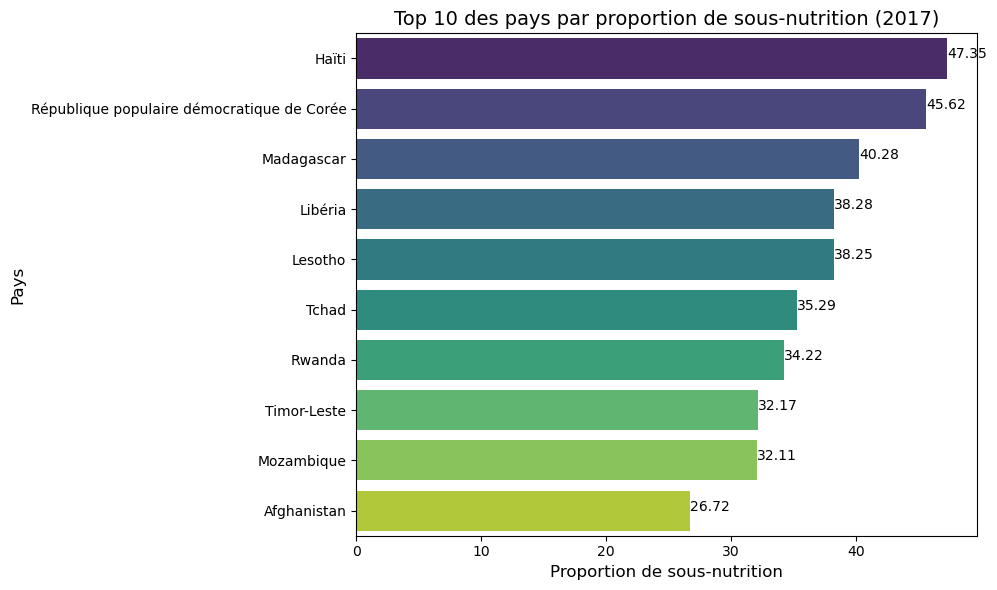

In [59]:
plt.figure(figsize=(10, 6))
sns.barplot(
    x='Proportion',
    y='Zone',
    data=top_10,
    palette='viridis'  # ou 'mako', 'rocket', etc.
)

# Ajouter des titres et des labels
plt.title('Top 10 des pays par proportion de sous-nutrition (2017)', fontsize=14)
plt.xlabel('Proportion de sous-nutrition', fontsize=12)
plt.ylabel('Pays', fontsize=12)
for index, value in enumerate(top_10['Proportion']):
    plt.text(value, index, f"{value:.2f}")


# Afficher le graphique
plt.tight_layout()
plt.show()

<div style="border: 1px solid RGB(0,150,250);" >
<h3 style="margin: auto; padding: 20px; color: RGB(0,150,250); ">3.7 - Pays qui ont le plus bénéficié d'aide alimentaire depuis 2013</h3>
</div>

In [60]:
#calcul du total de l'aide alimentaire par pays
total_aide_alimentaire = aide_alimentaire.groupby('Zone')['Valeur'].sum().reset_index()

In [61]:
#affichage après trie des 10 pays qui ont bénéficié le plus de l'aide alimentaire
total_aide_alimentaire.sort_values(by='Valeur', ascending=False).head(10)

,Zone,Valeur
50,République arabe syrienne,1858943000
75,Éthiopie,1381294000
70,Yémen,1206484000
61,Soudan du Sud,695248000
60,Soudan,669784000
30,Kenya,552836000
3,Bangladesh,348188000
59,Somalie,292678000
53,République démocratique du Congo,288502000
43,Niger,276344000


In [62]:
top_10_aide = total_aide_alimentaire.sort_values(by='Valeur', ascending=False).head(10)

/var/folders/t7/klgz_38n3yxgnnl73v7f3_gm0000gn/T/ipykernel_1550/3219964420.py:2: FutureWarning:



Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.




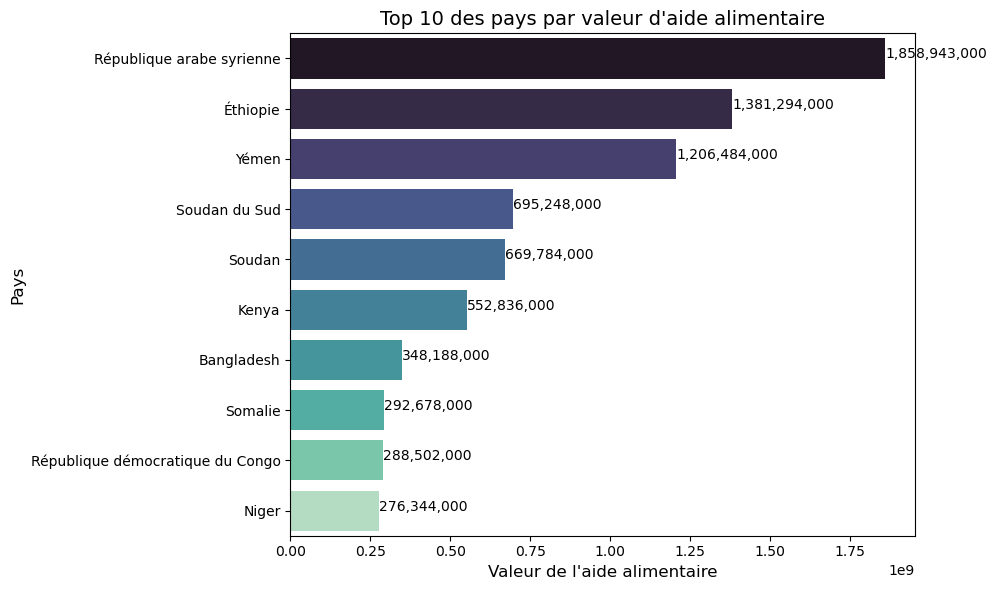

In [63]:
plt.figure(figsize=(10, 6))
sns.barplot(
    x='Valeur',
    y='Zone',  # ou le nom de la colonne contenant les pays
    data=top_10_aide,
    palette='mako'  # ou 'viridis', 'rocket', etc.
)

# Ajouter des titres et des labels
plt.title('Top 10 des pays par valeur d\'aide alimentaire', fontsize=14)
plt.xlabel('Valeur de l\'aide alimentaire', fontsize=12)
plt.ylabel('Pays', fontsize=12)
for index, value in enumerate(top_10_aide['Valeur']):
    plt.text(value, index, f"{value:,.0f}")


# Afficher le graphique
plt.tight_layout()
plt.show()

<div style="border: 1px solid RGB(0,150,250);" >
<h3 style="margin: auto; padding: 20px; color: RGB(0,150,250); ">3.8 - Evolution des 5 pays qui ont le plus bénéficiés de l'aide alimentaire entre 2013 et 2016</h3>
</div>

In [64]:
#Création d'un dataframe avec la zone, l'année et l'aide alimentaire puis groupby sur zone et année 
aide_2013_2016 = aide_alimentaire[
    (aide_alimentaire['Année'] >= 2013) &
    (aide_alimentaire['Année'] <= 2016)
]

aide_par_zone_annee = aide_2013_2016.groupby(['Zone', 'Année'])['Valeur'].sum().reset_index()

In [65]:
#Création d'une liste contenant les 5 pays qui ont le plus bénéficiées de l'aide alimentaire
total_aide_par_pays = aide_par_zone_annee.groupby('Zone')['Valeur'].sum().sort_values(ascending=False)

top_5_pays = total_aide_par_pays.head(5).index.tolist()

In [66]:
#On filtre sur le dataframe avec notre liste
aide_top_5_pays = aide_par_zone_annee[aide_par_zone_annee['Zone'].isin(top_5_pays)]

In [67]:
# Affichage des pays avec l'aide alimentaire par année
resultat = aide_top_5_pays.pivot(index='Année', columns='Zone', values='Valeur')
resultat

Zone,République arabe syrienne,Soudan,Soudan du Sud,Yémen,Éthiopie
Année,,,,,
2013,563566000.0,330230000.0,196330000.0,264764000.0,591404000.0
2014,651870000.0,321904000.0,450610000.0,103840000.0,586624000.0
2015,524949000.0,17650000.0,48308000.0,372306000.0,203266000.0
2016,118558000.0,NaN,NaN,465574000.0,NaN


In [68]:
resultat.to_csv('resultats.csv')

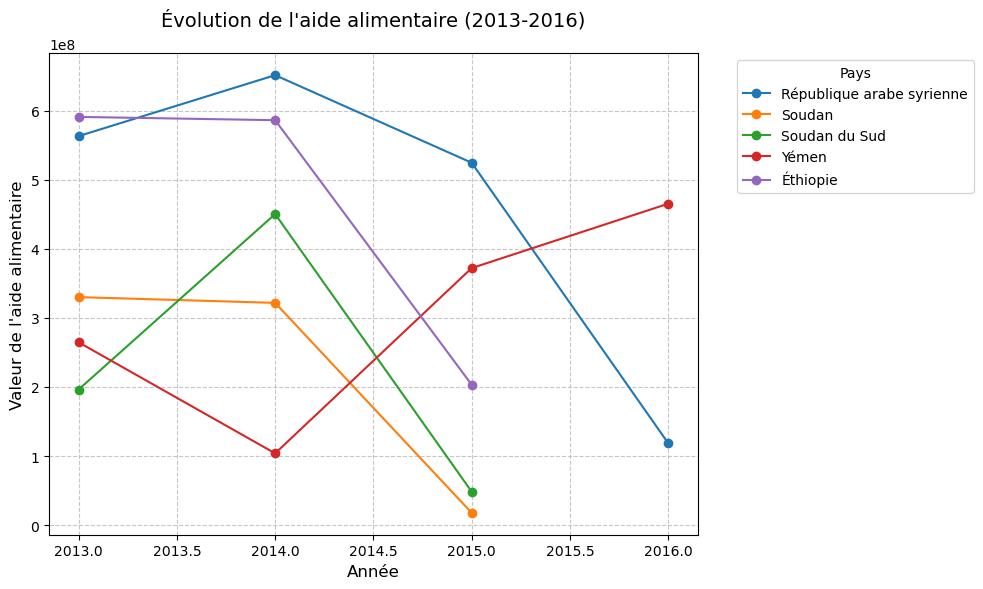

In [69]:
# Pas besoin de définir 'pays' manuellement, on utilise les colonnes du dataframe
pays = resultat.columns  # Liste des pays (colonnes du dataframe pivoté)

# Créer le graphique
plt.figure(figsize=(10, 6))

# Tracer une courbe pour chaque pays
for pays_nom in pays:
    plt.plot(resultat.index, resultat[pays_nom],
             marker='o',
             label=pays_nom)

# Personnaliser le graphique
plt.title("Évolution de l'aide alimentaire (2013-2016)", fontsize=14, pad=20)
plt.xlabel('Année', fontsize=12)
plt.ylabel("Valeur de l'aide alimentaire", fontsize=12)
plt.legend(title='Pays', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(True, linestyle='--', alpha=0.7)

# Ajuster la mise en page
plt.tight_layout()

# Afficher le graphique
plt.show()


<div style="border: 1px solid RGB(0,150,250);" >
<h3 style="margin: auto; padding: 20px; color: RGB(0,150,250); ">3.9 - Pays avec le moins de disponibilité par habitant</h3>
</div>

In [70]:
#Calcul de la disponibilité en kcal par personne par jour par pays
dispo_moyenne_par_habitant = dispo_alimentaire.groupby('Zone')['Disponibilité alimentaire (Kcal/personne/jour)'].mean().reset_index()

In [71]:
#Affichage des 10 pays qui ont le moins de dispo alimentaire par personne 
dispo_moyenne_par_habitant.sort_values(by='Disponibilité alimentaire (Kcal/personne/jour)', ascending=True).head(10)

,Zone,Disponibilité alimentaire (Kcal/personne/jour)
166,Zambie,20.688172
128,République centrafricaine,22.105882
91,Madagascar,22.347826
114,Ouganda,22.378947
134,République-Unie de Tanzanie,22.958333
167,Zimbabwe,22.967391
80,Kenya,22.968750
105,Namibie,23.042553
172,Éthiopie,23.141304
165,Yémen,23.838710


In [72]:
top_10_dmph = dispo_moyenne_par_habitant.sort_values(by='Disponibilité alimentaire (Kcal/personne/jour)', ascending=True).head(10)

In [73]:
# Appliquer une mise en forme conditionnelle (ex: couleur rouge pour les valeurs basses)
styled_top_10 = top_10_dmph.style.background_gradient(cmap='Reds_r', subset=['Disponibilité alimentaire (Kcal/personne/jour)'])
styled_top_10

,Zone,Disponibilité alimentaire (Kcal/personne/jour)
166,Zambie,20.688172
128,République centrafricaine,22.105882
91,Madagascar,22.347826
114,Ouganda,22.378947
134,République-Unie de Tanzanie,22.958333
167,Zimbabwe,22.967391
80,Kenya,22.968750
105,Namibie,23.042553
172,Éthiopie,23.141304
165,Yémen,23.838710


<div style="border: 1px solid RGB(0,150,250);" >
<h3 style="margin: auto; padding: 20px; color: RGB(0,150,250); ">3.10 - Pays avec le plus de disponibilité par habitant</h3>
</div>

In [74]:
#Affichage des 10 pays qui ont le plus de dispo alimentaire par personne 
dispo_moyenne_par_habitant.sort_values(by='Disponibilité alimentaire (Kcal/personne/jour)', ascending=False).head(10)

,Zone,Disponibilité alimentaire (Kcal/personne/jour)
158,Turkménistan,49.754386
84,Lesotho,47.698113
82,Kiribati,41.671233
159,Turquie,39.870968
11,Autriche,39.684211
74,Israël,39.670330
16,Belgique,39.336842
102,Monténégro,39.213483
138,Samoa,38.894737
83,Koweït,38.877778


In [75]:
top_10_dmph_2 = dispo_moyenne_par_habitant.sort_values(by='Disponibilité alimentaire (Kcal/personne/jour)', ascending=False).head(10)

In [76]:
styled_top_10_2 = top_10_dmph_2.style.background_gradient(cmap='Greens', subset=['Disponibilité alimentaire (Kcal/personne/jour)'])
styled_top_10_2

,Zone,Disponibilité alimentaire (Kcal/personne/jour)
158,Turkménistan,49.754386
84,Lesotho,47.698113
82,Kiribati,41.671233
159,Turquie,39.870968
11,Autriche,39.684211
74,Israël,39.670330
16,Belgique,39.336842
102,Monténégro,39.213483
138,Samoa,38.894737
83,Koweït,38.877778


<div style="border: 1px solid RGB(0,150,250);" >
<h3 style="margin: auto; padding: 20px; color: RGB(0,150,250); ">3.11 - Exemple de la Thaïlande pour le Manioc</h3>
</div>

In [ ]:
# Création d'un DataFrame pour les disponibilité de la Thailand

dispo_thaï = dispo_alimentaire[dispo_alimentaire['Zone'] == 'Thaïlande']
dispo_thaï_produit = dispo_thaï.groupby('Produit').sum()

# Les produits ayant le plus de production en Thailand

dispo_thaï_produit.sort_values(by=['Production'], ascending=False)

,Zone,Origine,Aliments pour animaux,Autres Utilisations,Disponibilité alimentaire (Kcal/personne/jour),Disponibilité alimentaire en quantité (kg/personne/an),Disponibilité de matière grasse en quantité (g/personne/jour),Disponibilité de protéines en quantité (g/personne/jour),Disponibilité intérieure,Exportations - Quantité,Importations - Quantité,Nourriture,Pertes,Production,Semences,Traitement,Variation de stock
Produit,,,,,,,,,,,,,,,,,
"Sucre, canne",Thaïlande,vegetale,0.0,0.000000e+00,49.0,61.11,0.33,0.17,1.000960e+11,0.000000e+00,0.000000e+00,4.095000e+09,1.001000e+09,1.000960e+11,0.0,9.500000e+10,0.000000e+00
Manioc,Thaïlande,vegetale,1800.0,2.081000e+09,40.0,13.00,0.05,0.14,6.264000e+09,2.521400e+10,1.250000e+09,8.710000e+08,1.511000e+09,3.022800e+10,0.0,0.000000e+00,0.000000e+00
Riz (Eq Blanchi),Thaïlande,vegetale,2405.0,0.000000e+00,1139.0,114.57,2.50,19.97,1.360500e+10,6.860000e+09,5.000000e+07,7.677000e+09,1.786000e+09,2.405400e+10,606000000.0,1.130000e+09,-3.638000e+09
Sucre Eq Brut,Thaïlande,vegetale,0.0,0.000000e+00,368.0,37.69,0.00,0.00,2.527000e+09,6.462000e+09,2.500000e+07,2.526000e+09,0.000000e+00,1.002400e+10,0.0,1.000000e+06,-1.060000e+09
"Fruits, Autres",Thaïlande,vegetale,0.0,0.000000e+00,63.0,57.56,0.56,0.72,3.791000e+09,2.671000e+09,2.610000e+08,3.857000e+09,3.960000e+08,6.141000e+09,0.0,6.000000e+06,6.000000e+07
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
Patates douces,Thaïlande,vegetale,0.0,0.000000e+00,1.0,0.21,0.00,0.01,1.500000e+07,0.000000e+00,1.500000e+07,1.400000e+07,2.000000e+06,0.000000e+00,0.0,0.000000e+00,0.000000e+00
Huile de Germe de Maïs,Thaïlande,vegetale,0.0,0.000000e+00,0.0,0.00,0.00,0.00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.0,0.000000e+00,0.000000e+00
Pommes,Thaïlande,vegetale,0.0,0.000000e+00,2.0,1.37,0.01,0.00,1.130000e+08,4.300000e+07,1.560000e+08,9.200000e+07,1.000000e+06,0.000000e+00,0.0,2.000000e+07,0.000000e+00


In [97]:
dispo_totale = dispo_thaï_produit['Disponibilité intérieure'].sum()

In [98]:
dispo_thaï_produit['Proportion Disponibilité intérieure'] = (
    dispo_thaï_produit['Disponibilité intérieure'] / dispo_totale * 100
)


In [107]:
resultat = dispo_thaï_produit[
    ['Disponibilité intérieure', 'Proportion Disponibilité intérieure']
]
pd.set_option('display.max_rows', None)

resultat

,Disponibilité intérieure,Proportion Disponibilité intérieure
Produit,,
Abats Comestible,7.400000e+07,0.046797
"Agrumes, Autres",8.000000e+06,0.005059
"Alcool, non Comestible",3.580000e+08,0.226396
Aliments pour enfants,1.200000e+07,0.007589
Ananas,7.820000e+08,0.494530
Animaux Aquatiques Autre,8.600000e+07,0.054386
Arachides Decortiquees,9.700000e+07,0.061342
Avoine,1.000000e+06,0.000632
Bananes,1.174000e+09,0.742427


,Disponibilité intérieure,Proportion Disponibilité intérieure
Produit,,
Abats Comestible,False,False
"Agrumes, Autres",False,False
"Alcool, non Comestible",False,False
Aliments pour enfants,False,False
Ananas,False,False
...,...,...
Viande de Suides,False,False
Viande de Volailles,False,False
"Viande, Autre",False,False


In [78]:
# Création d'un DataFrame pour connaitre les information de la disponibilité de manioc au sein de la Thailand

dispo_manioc_thaï = dispo_thaï[dispo_thaï['Produit'] == 'Manioc']
dispo_manioc_thaï

,Zone,Produit,Origine,Aliments pour animaux,Autres Utilisations,Disponibilité alimentaire (Kcal/personne/jour),Disponibilité alimentaire en quantité (kg/personne/an),Disponibilité de matière grasse en quantité (g/personne/jour),Disponibilité de protéines en quantité (g/personne/jour),Disponibilité intérieure,Exportations - Quantité,Importations - Quantité,Nourriture,Pertes,Production,Semences,Traitement,Variation de stock
13809,Thaïlande,Manioc,vegetale,1800.0,2.081000e+09,40.0,13.0,0.05,0.14,6.264000e+09,2.521400e+10,1.250000e+09,871000000.0,1.511000e+09,3.022800e+10,0.0,0.0,0.0


In [79]:
pop_thaï = population[(population['Année'] == 2017) & (population['Zone'] == 'Thaïlande')]
pop_thaï

,Zone,Année,Population
1312,Thaïlande,2017,69209810.0


In [80]:
#Calcul de la sous nutrition en Thaïlande
sous_nutrition_thailande = sous_nutrition[sous_nutrition['Zone'] == 'Thaïlande']
sous_nutrition_thailande

,Zone,Année,sous_nutrition
1110,Thaïlande,2012-2014,6200000.0
1111,Thaïlande,2013-2015,6000000.0
1112,Thaïlande,2014-2016,5900000.0
1113,Thaïlande,2015-2017,6000000.0
1114,Thaïlande,2016-2018,6200000.0
1115,Thaïlande,2017-2019,6500000.0


In [81]:
# On calcule la proportion exportée en fonction de la proportion
dispo_manioc_thaï['proportion_exportée'] = dispo_manioc_thaï['Exportations - Quantité'] / dispo_manioc_thaï['Production']

/var/folders/t7/klgz_38n3yxgnnl73v7f3_gm0000gn/T/ipykernel_1550/3352264952.py:2: SettingWithCopyWarning:


A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy



In [82]:
dispo_manioc_thaï[['Zone', 'Produit', 'Exportations - Quantité', 'Production', 'proportion_exportée']]


,Zone,Produit,Exportations - Quantité,Production,proportion_exportée
13809,Thaïlande,Manioc,2.521400e+10,3.022800e+10,0.834127


In [118]:
# Extraire les valeurs en tant que scalaires
dispo_kcal = dispo_manioc_thaï['Disponibilité alimentaire (Kcal/personne/jour)'].iloc[0]
population = pop_thaï['Population'].iloc[0]

# Calculer le pourcentage
pourcentage_nourri = (dispo_kcal * population) / (2100 * population) * 100
print(f"Pourcentage de la population nourrie : {pourcentage_nourri:.2f}%")


Pourcentage de la population nourrie : 1.90%


In [119]:
population_sous_alimentee = 6200000 
besoin_calorique_journalier = 2100
pourcentage_couverture = 10

# Besoin supplémentaire en kcal/jour
besoin_supplementaire_kcal_jour = (
    population_sous_alimentee * besoin_calorique_journalier * pourcentage_couverture / 100
)
print(f"Besoin supplémentaire en kcal/jour : {besoin_supplementaire_kcal_jour:.2f} kcal")


Besoin supplémentaire en kcal/jour : 1302000000.00 kcal


In [120]:
kcal_par_kg_manioc = 1500

quantite_manioc_necessaire_kg_jour = besoin_supplementaire_kcal_jour / kcal_par_kg_manioc
print(f"Quantité de manioc nécessaire en kg/jour : {quantite_manioc_necessaire_kg_jour:.2f} kg")


Quantité de manioc nécessaire en kg/jour : 868000.00 kg


In [121]:
exportations_actuelles_kg_jour = dispo_manioc_thaï['Exportations - Quantité'].iloc[0]
print(f"Exportations actuelles de manioc : {exportations_actuelles_kg_jour:.2f} kg/jour")

# Réduction nécessaire des exportations
reduction_exportations_kg_jour = min(quantite_manioc_necessaire_kg_jour, exportations_actuelles_kg_jour)
print(f"Réduction nécessaire des exportations : {reduction_exportations_kg_jour:.2f} kg/jour")


Exportations actuelles de manioc : 25214000000.00 kg/jour
Réduction nécessaire des exportations : 868000.00 kg/jour


In [122]:
# Disponibilité intérieure actuelle en kcal/jour
dispo_interieure_actuelle_kcal_jour = (
    dispo_manioc_thaï['Disponibilité intérieure'].iloc[0] * kcal_par_kg_manioc
)

# Nouvelle disponibilité intérieure
nouvelle_dispo_interieure_kcal_jour = (
    dispo_interieure_actuelle_kcal_jour + (reduction_exportations_kg_jour * kcal_par_kg_manioc)
)

print(f"Nouvelle disponibilité intérieure en kcal/jour : {nouvelle_dispo_interieure_kcal_jour:.2f} kcal")


Nouvelle disponibilité intérieure en kcal/jour : 9397302000000.00 kcal


In [125]:
population_totale = 69209810
nouveau_pourcentage_nourri = (
    (nouvelle_dispo_interieure_kcal_jour / (population_totale * besoin_calorique_journalier)) * 100
)
print(f"Nouveau pourcentage de la population nourrie : {nouveau_pourcentage_nourri:.2f}%")


Nouveau pourcentage de la population nourrie : 6465.71%


<div style="background-color: RGB(0,150,250);" >
<h2 style="margin: auto; padding: 20px; color:#fff; ">Etape 6 - Analyse complémentaires</h2>
</div>

Proportion de Aliments pour animaux : 13.23 %
Proportion de Pertes : 4.65 %
Proportion de Nourriture : 49.37 %
Proportion de Semences : 1.58 %
Proportion de Traitement : 22.45 %
Proportion de Autres Utilisations : 8.82 %

In [83]:
#ajouter en dessous toutes les analyses complémtaires